# SC4002 Group Assignment: joint intent classification and slot filling (MASSIVE 1.0, en-US)

Run all cells top to bottom on a Colab GPU runtime and keep the outputs. Do not clear outputs or edit logged numbers by hand.

1. Setup, data loading and verification
2. Preprocessing (train-only vocabularies, contraction-aware word vectors)
3. Shared evaluation functions (identical for every experiment)
4. Training loop (identical for every experiment)
5. Stage 1: baseline (tuning on dev with 3 seeds, final run, checkpoint, final evaluation, error analysis)
6. Stage 2: AI-enhanced system (ablation on dev, final run, checkpoint, final evaluation)
7. Results table

## 1. Setup, data loading and verification

In [ ]:
!pip -q install gensim seqeval
!wget -q -nc https://amazon-massive-nlu-dataset.s3.amazonaws.com/amazon-massive-dataset-1.0.tar.gz
!tar -xzf amazon-massive-dataset-1.0.tar.gz

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import json, re, glob, random, time, itertools, collections
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
import gensim.downloader as api
from IPython.display import display

PARAM_CAP = 20_000_000
PAD, UNK, IGNORE = 0, 1, -100
NEG = -1e4
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

device: cuda


In [ ]:
path = glob.glob('1.0/**/en-US.jsonl', recursive=True)[0]
raw = {'train': [], 'dev': [], 'test': []}
with open(path, encoding='utf-8') as f:
    for line in f:
        if line.strip():
            r = json.loads(line)
            raw[r['partition']].append(r)
print({k: len(v) for k, v in raw.items()})
assert len(raw['train']) == 11514
assert len(raw['dev']) == 2033
assert len(raw['test']) == 2974
assert sum(len(v) for v in raw.values()) == 16521
print('split sizes verified')

{'train': 11514, 'dev': 2033, 'test': 2974}
split sizes verified


## 2. Preprocessing
The model input is `utt` only. Labels come from `intent` and `annot_utt`. The parser asserts that the words read from `annot_utt` equal `utt.split()` for every row, so words and tags can never be misaligned.

In [ ]:
ENT = re.compile(r'\[(\w+) : ([^\]]*)\]')

def parse_annot(annot):
    tokens, tags, pos = [], [], 0
    for m in ENT.finditer(annot):
        for w in annot[pos:m.start()].split():
            tokens.append(w); tags.append('O')
        for i, w in enumerate(m.group(2).split()):
            tokens.append(w); tags.append(('B-' if i == 0 else 'I-') + m.group(1))
        pos = m.end()
    for w in annot[pos:].split():
        tokens.append(w); tags.append('O')
    return tokens, tags

data = {}
for split, rows in raw.items():
    data[split] = []
    for r in rows:
        toks, tags = parse_annot(r['annot_utt'])
        assert toks == r['utt'].split(), r['id']
        data[split].append((toks, r['intent'], tags))
print('annotation parsing verified on all rows')

intents = sorted({x[1] for x in data['train']})
slot_types = sorted({t[2:] for x in data['train'] for t in x[2] if t != 'O'})
tag_list = ['O'] + [p + s for s in slot_types for p in ('B-', 'I-')]
intent2id = {k: i for i, k in enumerate(intents)}
tag2id = {k: i for i, k in enumerate(tag_list)}
assert len(intents) == 60 and len(slot_types) == 55 and len(tag_list) == 111
print(len(intents), 'intents,', len(slot_types), 'slot types,', len(tag_list), 'BIO tags')

# Vocabularies from the TRAIN split only. Unseen words and characters map to <unk>.
word_counts = collections.Counter(w.lower() for toks, _, _ in data['train'] for w in toks)
vocab = ['<pad>', '<unk>'] + sorted(word_counts)
word2id = {w: i for i, w in enumerate(vocab)}
chars = ['<pad>', '<unk>'] + sorted({c for w in word_counts for c in w})
char2id = {c: i for i, c in enumerate(chars)}
MAX_CHARS = 20
print('train vocab:', len(vocab), 'words,', len(chars), 'characters')
dev_oov = sum(w.lower() not in word2id for toks, _, _ in data['dev'] for w in toks)
print(f"dev OOV tokens: {100 * dev_oov / sum(len(x[0]) for x in data['dev']):.2f}%")

annotation parsing verified on all rows
60 intents, 55 slot types, 111 BIO tags
train vocab: 5304 words, 34 characters
dev OOV tokens: 3.32%


### Word vectors
Only pretrained word vectors are used (allowed), kept for train-vocabulary words only, and the whole matrix is counted in the parameter total. Two details matter for quality:
- Contractions: GloVe and fastText store `what's` as `what` + `'s`, so an unseen contraction takes the mean of its pieces (otherwise very frequent words such as `what's` or `don't` would get no vector).
- Scale: GloVe and fastText differ about 14x in raw scale. Each table is rescaled to std 0.4 so that concatenating them does not let one drown the other. Words with no vector get a fixed random vector, and `<unk>` gets the mean vector.

In [ ]:
KV_NAMES = {'glove': 'glove-wiki-gigaword-300', 'fasttext': 'fasttext-wiki-news-subwords-300'}
_kv_cache = {}
def get_kv(key):
    if key not in _kv_cache:
        _kv_cache[key] = api.load(KV_NAMES[key])
    return _kv_cache[key]

def find(w, kv):
    for v in (w, w.capitalize(), w.upper()):
        if v in kv:
            return kv[v]
    return None

def lookup(w, kv):
    v = find(w, kv)
    if v is None and "'" in w:
        i = len(w) - 3 if w.endswith("n't") else w.index("'")
        pieces = [find(w[:i], kv), find(w[i:], kv)]
        if all(p is not None for p in pieces):
            v = np.mean(pieces, axis=0)
    return v

TARGET_STD = 0.4
_table_cache = {}
def vector_table(key):
    if key in _table_cache:
        return _table_cache[key]
    kv = get_kv(key)
    mat = np.zeros((len(vocab), 300), dtype=np.float32)
    found = np.zeros(len(vocab), dtype=bool)
    for w, i in word2id.items():
        if i < 2:
            continue
        v = lookup(w, kv)
        if v is not None:
            mat[i], found[i] = v, True
    mat[found] *= TARGET_STD / mat[found].std()
    rng = np.random.default_rng(0)
    missing = ~found; missing[:2] = False
    mat[missing] = rng.normal(0, TARGET_STD, size=(int(missing.sum()), 300))
    mat[UNK] = mat[found].mean(0)
    print(f"{key}: {int(missing.sum())} of {len(vocab) - 2} train words have no vector ({100 * missing.sum() / (len(vocab) - 2):.2f}%)")
    _table_cache[key] = mat
    return mat

def build_embedding_matrix(emb):
    keys = ['glove', 'fasttext'] if emb == 'both' else [emb]
    return np.concatenate([vector_table(k) for k in keys], axis=1)

In [ ]:
def encode(split):
    out = []
    for toks, intent, tags in data[split]:
        out.append(dict(words=[word2id.get(w.lower(), UNK) for w in toks],
                        chars=[[char2id.get(c, UNK) for c in w.lower()[:MAX_CHARS]] for w in toks],
                        intent=intent2id[intent], tags=[tag2id[t] for t in tags]))
    return out
enc = {k: encode(k) for k in data}

def collate(batch):
    B, T = len(batch), max(len(x['words']) for x in batch)
    C = max(len(c) for x in batch for c in x['chars'])
    words = torch.full((B, T), PAD, dtype=torch.long)
    chrs = torch.full((B, T, C), PAD, dtype=torch.long)
    tags = torch.full((B, T), IGNORE, dtype=torch.long)
    for i, x in enumerate(batch):
        n = len(x['words'])
        words[i, :n] = torch.tensor(x['words'])
        tags[i, :n] = torch.tensor(x['tags'])
        for j, cs in enumerate(x['chars']):
            chrs[i, j, :len(cs)] = torch.tensor(cs)
    return dict(words=words, chars=chrs, tags=tags, mask=words != PAD,
                intents=torch.tensor([x['intent'] for x in batch]))

def make_loader(split, batch_size, shuffle):
    return torch.utils.data.DataLoader(enc[split], batch_size=batch_size, shuffle=shuffle, collate_fn=collate)

def to_dev(batch, dev):
    return {k: v.to(dev) for k, v in batch.items()}

## 3. Shared evaluation functions
Every model implements `loss(batch)` and `decode(batch)` (intent ids and a list of tag-id lists). Training and evaluation code is then identical for both stages.

- Intent accuracy = 100 x correct / total.
- Slot micro F1: for each utterance, gold and predicted slots are multisets of (slot type, span text) pairs. TP, FP and FN are pooled over all utterances and F1 = 100 x 2TP / (2TP + FP + FN). A boundary or type error costs one FP and one FN.
- Exact match (intent right and all slots right) is a diagnostic. The selection score is the combined score (intent accuracy + slot F1) / 2.
- A span is read from BIO tags: `B-x` starts a span, `I-x` continues a span of the same type, and a stray `I-x` starts a new span.

In [ ]:
def tags_to_spans(tags):
    spans, start, typ = [], None, None
    for i, t in enumerate(list(tags) + ['O']):
        if t == 'O' or t.startswith('B-') or t[2:] != typ:
            if typ is not None:
                spans.append((typ, start, i))
            typ, start = (t[2:], i) if t != 'O' else (None, None)
    return spans

def slot_pairs(tokens, tags):
    return collections.Counter((t, ' '.join(tokens[s:e])) for t, s, e in tags_to_spans(tags))

def compute_metrics(gold_i, pred_i, tokens, gold_t, pred_t):
    tp = fp = fn = exact = correct = 0
    for gi, pi, tok, g, p in zip(gold_i, pred_i, tokens, gold_t, pred_t):
        gs, ps = slot_pairs(tok, g), slot_pairs(tok, p)
        hit = sum((gs & ps).values())
        tp += hit; fp += sum(ps.values()) - hit; fn += sum(gs.values()) - hit
        ok = gi == pi
        correct += ok; exact += ok and gs == ps
    n = len(gold_i)
    intent_acc = 100.0 * correct / n
    slot_f1 = 100.0 * 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 0.0
    return dict(intent_acc=intent_acc, slot_f1=slot_f1, exact=100.0 * exact / n, score=(intent_acc + slot_f1) / 2)

# unit tests of the metric
_tok = 'wake me up at five am'.split()
_g = ['O', 'O', 'O', 'O', 'B-time', 'I-time']
assert compute_metrics([0], [0], [_tok], [_g], [_g])['slot_f1'] == 100.0
_m = compute_metrics([0], [0], [_tok], [_g], [['O', 'O', 'O', 'O', 'B-time', 'O']])   # boundary error: 1 FP + 1 FN
assert _m['slot_f1'] == 0.0 and _m['exact'] == 0.0
assert tags_to_spans(['I-a', 'I-a', 'B-a', 'I-b']) == [('a', 0, 2), ('a', 2, 3), ('b', 3, 4)]
print('metric unit tests pass')

@torch.no_grad()
def predict_split(model, split, batch_size=256):
    model.eval()
    dev = next(model.parameters()).device
    pi, pt, tot, n = [], [], 0.0, 0
    for batch in make_loader(split, batch_size, False):
        batch = to_dev(batch, dev)
        bs = batch['words'].size(0)
        tot += model.loss(batch).item() * bs; n += bs
        i, t = model.decode(batch)
        pi += i; pt += [[tag_list[x] for x in p] for p in t]
    return pi, pt, tot / n

def evaluate(model, split):
    pi, pt, loss = predict_split(model, split)
    ex = data[split]
    m = compute_metrics([intent2id[x[1]] for x in ex], pi, [x[0] for x in ex], [x[2] for x in ex], pt)
    m['loss'] = loss
    return m

def count_params(model):
    return (sum(p.numel() for p in model.parameters()),
            sum(p.numel() for p in model.parameters() if p.requires_grad))

metric unit tests pass


## 4. Training loop
Logs epoch-level training loss, validation loss, validation metrics and elapsed time. Saves the checkpoint with the highest validation combined score and returns the history for learning curves. Training loss is measured with dropout on, so it can sit above the validation loss.

In [ ]:
def word_drop_probs(alpha):
    # hide word w as <unk> with probability alpha / (alpha + count(w)): rare words are hidden more often
    p = torch.zeros(len(vocab))
    for w, i in word2id.items():
        if i >= 2:
            p[i] = alpha / (alpha + word_counts[w])
    return p

def train(build_fn, cfg, ckpt_path, seed, verbose=True):
    set_seed(seed)
    model = build_fn(cfg).to(device)
    total, trainable = count_params(model)
    assert total <= PARAM_CAP, f'{total} parameters exceeds the 20M cap'
    if verbose:
        print(f'total params {total:,} | trainable {trainable:,} | within 20M cap: {total <= PARAM_CAP}')
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=cfg['lr'])
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode='max', factor=0.5, patience=3)
    pdrop = word_drop_probs(cfg['wd_alpha']).to(device) if cfg['wd_alpha'] > 0 else None
    loader = make_loader('train', cfg['batch'], True)
    hist, best, best_ep, bad, t0 = [], -1.0, 0, 0, time.time()
    for ep in range(1, cfg['max_epochs'] + 1):
        model.train()
        tot, n = 0.0, 0
        for batch in loader:
            batch = to_dev(batch, device)
            if pdrop is not None:
                hide = (torch.rand(batch['words'].shape, device=device) < pdrop[batch['words']]) & batch['mask']
                batch['words'] = batch['words'].masked_fill(hide, UNK)
            loss = model.loss(batch)
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), cfg['clip'])
            opt.step()
            bs = batch['words'].size(0)
            tot += loss.item() * bs; n += bs
        v = evaluate(model, 'dev')
        sched.step(v['score'])
        hist.append(dict(epoch=ep, train_loss=tot / n, val_loss=v['loss'], val_intent_acc=v['intent_acc'],
                         val_slot_f1=v['slot_f1'], val_score=v['score'], elapsed_s=time.time() - t0))
        improved = v['score'] > best
        if improved:
            best, best_ep, bad = v['score'], ep, 0
            torch.save(model.state_dict(), ckpt_path)
        else:
            bad += 1
        if verbose:
            print(f"ep {ep:3d} | train loss {tot/n:.4f} | val loss {v['loss']:.4f} | intent {v['intent_acc']:.2f} | "
                  f"slot F1 {v['slot_f1']:.2f} | score {v['score']:.2f} | {time.time()-t0:6.1f}s {'*' if improved else ''}")
        if bad >= cfg['patience']:
            if verbose: print(f'early stopping at epoch {ep}')
            break
    return pd.DataFrame(hist), best_ep, best

def plot_curves(hist, title):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
    ax[0].plot(hist.epoch, hist.train_loss, label='train loss')
    ax[0].plot(hist.epoch, hist.val_loss, label='validation loss')
    ax[0].set_xlabel('epoch'); ax[0].set_ylabel('loss'); ax[0].legend(); ax[0].set_title(title + ': loss')
    ax[1].plot(hist.epoch, hist.val_intent_acc, label='intent accuracy')
    ax[1].plot(hist.epoch, hist.val_slot_f1, label='slot micro F1')
    ax[1].set_xlabel('epoch'); ax[1].set_ylabel('%'); ax[1].legend(); ax[1].set_title(title + ': validation')
    plt.tight_layout(); plt.show()

def tune(build_fn, base, grid, seeds, tag):
    rows = []
    for gi, change in enumerate(grid):
        cfg, res = {**base, **change}, []
        for s in seeds:
            hist, ep, _ = train(build_fn, cfg, f'tmp_{tag}_{gi}_{s}.pt', s, verbose=False)
            res.append(hist.loc[ep - 1])
        f = lambda c: f"{np.mean([r[c] for r in res]):.2f} +- {np.std([r[c] for r in res]):.2f}"
        rows.append(dict(run=gi, change=str(change), intent=f('val_intent_acc'), slot_f1=f('val_slot_f1'),
                         combined=f('val_score'), mean_combined=np.mean([r['val_score'] for r in res]),
                         mean_best_epoch=np.mean([r['epoch'] for r in res])))
        print(f"run {gi} {change}: combined {rows[-1]['combined']}", flush=True)
    return pd.DataFrame(rows)

def final_eval(build_fn, cfg, ckpt_path, best_score, name, epochs_trained, best_epoch):
    model = build_fn(cfg).to(device)
    model.load_state_dict(torch.load(ckpt_path, map_location=device))
    total, trainable = count_params(model)
    assert total <= PARAM_CAP
    dev, test = evaluate(model, 'dev'), evaluate(model, 'test')
    assert abs(dev['score'] - best_score) < 1e-6, 'validation score does not match the saved best'
    print(f'{name}: total params {total:,} | trainable {trainable:,}')
    print(f"validation: intent acc {dev['intent_acc']:.2f} | slot micro F1 {dev['slot_f1']:.2f} (matches best epoch {best_epoch})")
    print(f"test:       intent acc {test['intent_acc']:.2f} | slot micro F1 {test['slot_f1']:.2f}")
    return dict(name=name, total=total, trainable=trainable, dev=dev, test=test,
                epochs_trained=epochs_trained, best_epoch=best_epoch), model

## 5. Stage 1: baseline joint BiLSTM

One network and one loss. Input: lower-cased words of `utt` mapped to frozen pretrained vectors (GloVe, fastText or both concatenated). Encoder: a 2-layer bidirectional LSTM (256 per direction). Intent head: max-pooling over the word states, then a linear layer over 60 intents. Slot head: a linear layer over each word state predicting one of 111 BIO tags independently. Loss: lambda x intent cross-entropy + (1 - lambda) x token-level slot cross-entropy with lambda = 0.5. Optimiser: Adam with gradient clipping and ReduceLROnPlateau on the validation combined score. Checkpoint: highest validation combined score.

The same class also holds the optional extras used in Stage 2 (character CNN, CRF, label smoothing, word dropout). Every extra is switched off for the baseline.

In [ ]:
class CharCNN(nn.Module):
    def __init__(self, n_chars, char_dim=50, filters=100, width=3):
        super().__init__()
        self.emb = nn.Embedding(n_chars, char_dim, padding_idx=PAD)
        self.conv = nn.Conv1d(char_dim, filters, width, padding=width // 2)
        self.out_dim = filters

    def forward(self, chars):                                   # [B,T,C] -> [B,T,filters]
        B, T, C = chars.shape
        flat = chars.reshape(B * T, C)
        x = F.relu(self.conv(self.emb(flat).transpose(1, 2)))
        x = x.masked_fill((flat == PAD).unsqueeze(1), 0.0)
        return x.max(dim=2).values.view(B, T, -1)

def bio_constraints(tags):
    K = len(tags)
    allow = torch.ones(K, K, dtype=torch.bool)
    start_ok = torch.ones(K, dtype=torch.bool)
    for j, t in enumerate(tags):
        if t.startswith('I-'):
            start_ok[j] = False
            for i, p in enumerate(tags):
                allow[i, j] = p != 'O' and p[2:] == t[2:]
    return allow, start_ok

class CRF(nn.Module):
    # linear-chain CRF whose illegal BIO moves (O -> I-x, B-x -> I-y, ...) are blocked by a large negative score
    def __init__(self, tags):
        super().__init__()
        K = len(tags)
        self.trans = nn.Parameter(torch.zeros(K, K))
        self.start = nn.Parameter(torch.zeros(K))
        self.end = nn.Parameter(torch.zeros(K))
        allow, start_ok = bio_constraints(tags)
        self.register_buffer('allow', allow)
        self.register_buffer('start_ok', start_ok)

    def _tr(self):  return self.trans + (~self.allow).float() * NEG
    def _st(self):  return self.start + (~self.start_ok).float() * NEG

    def score(self, em, tags, mask):
        tags = tags.clamp(min=0)
        tr = self._tr()
        s = self._st()[tags[:, 0]] + em[:, 0].gather(1, tags[:, :1]).squeeze(1)
        for t in range(1, em.size(1)):
            step = tr[tags[:, t - 1], tags[:, t]] + em[:, t].gather(1, tags[:, t:t + 1]).squeeze(1)
            s = s + step * mask[:, t].float()
        last = mask.long().sum(1) - 1
        return s + self.end[tags.gather(1, last.unsqueeze(1)).squeeze(1)]

    def log_partition(self, em, mask):
        tr = self._tr()
        alpha = self._st() + em[:, 0]
        for t in range(1, em.size(1)):
            nxt = torch.logsumexp(alpha.unsqueeze(2) + tr.unsqueeze(0), dim=1) + em[:, t]
            alpha = torch.where(mask[:, t].unsqueeze(1), nxt, alpha)
        return torch.logsumexp(alpha + self.end, dim=1)

    def nll(self, em, tags, mask):
        return self.log_partition(em, mask) - self.score(em, tags, mask)

    @torch.no_grad()
    def viterbi(self, em, mask):
        tr = self._tr()
        score, hist = self._st() + em[:, 0], []
        for t in range(1, em.size(1)):
            best, idx = (score.unsqueeze(2) + tr.unsqueeze(0)).max(dim=1)
            score = torch.where(mask[:, t].unsqueeze(1), best + em[:, t], score)
            hist.append(idx)
        last = (score + self.end).argmax(1).tolist()
        lengths = mask.long().sum(1).tolist()
        paths = []
        for b in range(em.size(0)):
            tag, path = last[b], [last[b]]
            for t in range(lengths[b] - 1, 0, -1):
                tag = int(hist[t - 1][b, tag]); path.append(tag)
            paths.append(path[::-1])
        return paths

class JointBiLSTM(nn.Module):
    def __init__(self, emb_matrix, cfg):
        super().__init__()
        self.cfg = cfg
        self.emb = nn.Embedding.from_pretrained(torch.tensor(emb_matrix), freeze=cfg['freeze_emb'], padding_idx=PAD)
        self.char = CharCNN(len(chars)) if cfg['char_cnn'] else None
        d_in = emb_matrix.shape[1] + (self.char.out_dim if self.char else 0)
        self.drop = nn.Dropout(cfg['dropout'])
        self.lstm = nn.LSTM(d_in, cfg['hidden'], cfg['layers'], batch_first=True, bidirectional=True,
                            dropout=cfg['dropout'] if cfg['layers'] > 1 else 0.0)
        d = 2 * cfg['hidden']
        self.intent_head = nn.Linear(d, len(intents))
        self.slot_head = nn.Linear(d, len(tag_list))
        self.crf = CRF(tag_list) if cfg['crf'] else None

    def heads(self, b):
        e = self.emb(b['words'])
        if self.char is not None:
            e = torch.cat([e, self.char(b['chars'])], dim=-1)
        packed = pack_padded_sequence(self.drop(e), b['mask'].sum(1).cpu(), batch_first=True, enforce_sorted=False)
        out, _ = self.lstm(packed)
        out, _ = pad_packed_sequence(out, batch_first=True, total_length=b['words'].size(1))
        out = self.drop(out)
        pooled = out.masked_fill(~b['mask'].unsqueeze(-1), -1e9).max(dim=1).values   # max-pooling over words
        return self.intent_head(pooled), self.slot_head(out)

    def loss(self, b):
        li, em = self.heads(b)
        l_int = F.cross_entropy(li, b['intents'], label_smoothing=self.cfg['label_smoothing'])
        if self.crf is None:
            l_slot = F.cross_entropy(em.reshape(-1, em.size(-1)), b['tags'].reshape(-1), ignore_index=IGNORE)
        else:
            l_slot = self.crf.nll(em, b['tags'], b['mask']).mean()
        return self.cfg['lam'] * l_int + (1 - self.cfg['lam']) * l_slot

    @torch.no_grad()
    def decode(self, b):
        li, em = self.heads(b)
        if self.crf is not None:
            paths = self.crf.viterbi(em, b['mask'])
        else:
            pt, lengths = em.argmax(-1), b['mask'].sum(1).tolist()
            paths = [pt[i, :lengths[i]].tolist() for i in range(pt.size(0))]
        return li.argmax(-1).tolist(), paths

def build_model(cfg):
    return JointBiLSTM(build_embedding_matrix(cfg['emb']), cfg)

BASE = dict(emb='glove', freeze_emb=True, hidden=256, layers=2, dropout=0.3, lam=0.5,
            char_cnn=False, crf=False, label_smoothing=0.0, wd_alpha=0.0,
            lr=1e-3, batch=64, clip=5.0, max_epochs=100, patience=8)
m = build_model(BASE)
print('baseline parameters (total, trainable):', count_params(m))
del m

[==================================================] 100.0% 376.1/376.1MB downloaded
glove: 184 of 5302 train words have no vector (3.47%)
baseline parameters (total, trainable): (4398667, 2807467)


### Check the CRF
Log Z and Viterbi must equal brute force over every tag sequence, and Viterbi must never output an illegal BIO sequence. Run this before trusting any CRF number.

In [ ]:
def crf_self_test():
    torch.manual_seed(0)
    tags = ['O', 'B-a', 'I-a', 'B-b', 'I-b']
    crf = CRF(tags)
    with torch.no_grad():
        for p in crf.parameters():
            p.normal_()
    em = torch.randn(2, 4, 5)
    mask = torch.tensor([[1, 1, 1, 1], [1, 1, 1, 0]], dtype=torch.bool)
    for b in range(2):
        L = int(mask[b].sum())
        scored = [(crf.score(em[b:b+1], torch.tensor([list(s) + [0] * (4 - L)]), mask[b:b+1]).item(), s)
                  for s in itertools.product(range(5), repeat=L)]
        logz = crf.log_partition(em[b:b+1], mask[b:b+1]).item()
        assert abs(logz - torch.logsumexp(torch.tensor([x for x, _ in scored]), 0).item()) < 1e-3
        assert tuple(crf.viterbi(em[b:b+1], mask[b:b+1])[0]) == max(scored)[1]
    paths = crf.viterbi(torch.randn(32, 9, 5) * 3, torch.ones(32, 9, dtype=torch.bool))
    for p in paths:
        names = [tags[i] for i in p]
        assert all(not (n.startswith('I-') and (i == 0 or names[i - 1] == 'O' or names[i - 1][2:] != n[2:])) for i, n in enumerate(names))
    print('CRF checks pass: log Z and Viterbi match brute force; constrained paths are always legal')
crf_self_test()

CRF checks pass: log Z and Viterbi match brute force; constrained paths are always legal


### Baseline tuning (validation only, 3 seeds)
Seed-to-seed noise is about 0.3 to 0.6 points, as large as many effects, so every setting is trained with 3 seeds and compared by its mean validation combined score. The test split is not touched. The setting with the best mean becomes the baseline automatically.

In [ ]:
TUNE_SEEDS = [0, 1, 2]
GRID1 = [dict(), dict(dropout=0.4), dict(emb='fasttext'), dict(emb='both')]
tuning1 = tune(build_model, BASE, GRID1, TUNE_SEEDS, 's1')
display(tuning1.drop(columns='mean_combined'))
BASELINE_CFG = {**BASE, **GRID1[int(tuning1.mean_combined.idxmax())]}
print('selected baseline configuration:', BASELINE_CFG)

run 0 {}: combined 82.36 +- 0.23
run 1 {'dropout': 0.4}: combined 82.67 +- 0.19
[==================================================] 100.0% 958.5/958.4MB downloaded
fasttext: 140 of 5302 train words have no vector (2.64%)
run 2 {'emb': 'fasttext'}: combined 82.56 +- 0.11
run 3 {'emb': 'both'}: combined 82.82 +- 0.13


,run,change,intent,slot_f1,combined,mean_best_epoch
0,0,{},86.62 +- 0.04,78.11 +- 0.49,82.36 +- 0.23,42.666667
1,1,{'dropout': 0.4},86.87 +- 0.22,78.48 +- 0.61,82.67 +- 0.19,45.333333
2,2,{'emb': 'fasttext'},87.00 +- 0.20,78.12 +- 0.10,82.56 +- 0.11,30.666667
3,3,{'emb': 'both'},87.18 +- 0.29,78.45 +- 0.06,82.82 +- 0.13,36.666667


selected baseline configuration: {'emb': 'both', 'freeze_emb': True, 'hidden': 256, 'layers': 2, 'dropout': 0.3, 'lam': 0.5, 'char_cnn': False, 'crf': False, 'label_smoothing': 0.0, 'wd_alpha': 0.0, 'lr': 0.001, 'batch': 64, 'clip': 5.0, 'max_epochs': 100, 'patience': 8}


### Train the final Stage-1 baseline (fresh seed) and select its checkpoint

total params 6,604,267 | trainable 3,421,867 | within 20M cap: True
ep   1 | train loss 1.9355 | val loss 1.0350 | intent 63.50 | slot F1 35.30 | score 49.40 |    4.7s *
ep   2 | train loss 0.7610 | val loss 0.6097 | intent 79.24 | slot F1 54.89 | score 67.06 |    8.6s *
ep   3 | train loss 0.5033 | val loss 0.5042 | intent 82.10 | slot F1 64.58 | score 73.34 |   12.4s *
ep   4 | train loss 0.3887 | val loss 0.4598 | intent 84.36 | slot F1 69.27 | score 76.81 |   17.1s *
ep   5 | train loss 0.3112 | val loss 0.4347 | intent 84.95 | slot F1 72.07 | score 78.51 |   21.0s *
ep   6 | train loss 0.2570 | val loss 0.4106 | intent 85.83 | slot F1 71.89 | score 78.86 |   24.8s *
ep   7 | train loss 0.2119 | val loss 0.4170 | intent 85.69 | slot F1 73.10 | score 79.39 |   29.6s *
ep   8 | train loss 0.1800 | val loss 0.4183 | intent 85.78 | slot F1 74.17 | score 79.98 |   33.5s *
ep   9 | train loss 0.1477 | val loss 0.4069 | intent 86.28 | slot F1 75.72 | score 81.00 |   37.3s *
ep  10 | train

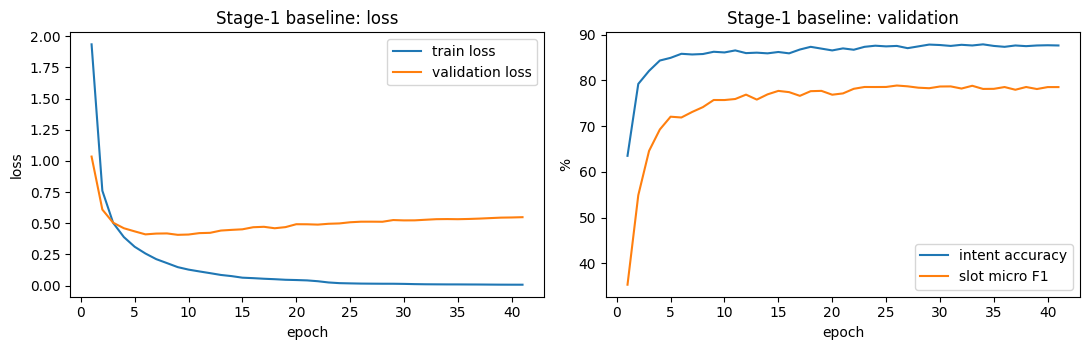

In [ ]:
FINAL_SEED = 100
BASELINE_CKPT = 'stage1_baseline_best.pt'
hist1, best_ep1, best_score1 = train(build_model, BASELINE_CFG, BASELINE_CKPT, FINAL_SEED)
print(f'\nBest checkpoint: epoch {best_ep1} | validation combined score {best_score1:.4f} | file {BASELINE_CKPT}')
plot_curves(hist1, 'Stage-1 baseline')
hist1.to_csv('stage1_history.csv', index=False)

### Final evaluation of the saved Stage-1 checkpoint (no further training)

In [ ]:
RESULTS = {}
RESULTS['Stage-1 system'], stage1_model = final_eval(build_model, BASELINE_CFG, BASELINE_CKPT, best_score1,
                                                     'Stage-1 system', len(hist1), best_ep1)

# cross-check of the shared slot metric against seqeval on the real dev predictions
from seqeval.metrics import f1_score as seqeval_f1
_pi, _pt, _ = predict_split(stage1_model, 'dev')
_sq = 100 * seqeval_f1([x[2] for x in data['dev']], _pt)
_ours = RESULTS['Stage-1 system']['dev']['slot_f1']
print(f'shared metric {_ours:.2f} vs seqeval {_sq:.2f}')
assert abs(_sq - _ours) < 0.2

Stage-1 system: total params 6,604,267 | trainable 3,421,867
validation: intent acc 87.65 | slot micro F1 78.83 (matches best epoch 33)
test:       intent acc 85.94 | slot micro F1 75.40
shared metric 78.83 vs seqeval 78.83


### Error analysis of the Stage-1 baseline (dev)
These tables are the evidence for choosing Stage-2 changes: invalid tag sequences motivate a CRF, unseen-word recall motivates character features and word dropout, and confused intents show where the intent head is weak.

In [ ]:
def error_analysis(model, split='dev'):
    pi, pt, _ = predict_split(model, split)
    ex = data[split]
    stray = sum(1 for tags in pt for p, t in zip(['O'] + tags[:-1], tags) if t.startswith('I-') and p[2:] != t[2:])
    print('stray I- tags (invalid BIO) in predictions:', stray)

    kinds, oov = collections.Counter(), collections.Counter()
    per_type = collections.defaultdict(lambda: [0, 0, 0])            # tp, fp, fn
    for (toks, _, gtags), ptags in zip(ex, pt):
        G, P = set(tags_to_spans(gtags)), set(tags_to_spans(ptags))
        overlap = lambda a, b: a[1] < b[2] and b[1] < a[2]
        for p in P:
            if p in G:
                kinds['exact'] += 1
            elif any(g[1:] == p[1:] and g[0] != p[0] for g in G):
                kinds['type error'] += 1
            elif any(overlap(g, p) and g[0] == p[0] for g in G):
                kinds['boundary error'] += 1
            elif any(overlap(g, p) for g in G):
                kinds['type + boundary'] += 1
            else:
                kinds['spurious'] += 1
        for g in G:
            has_oov = any(w.lower() not in word2id for w in toks[g[1]:g[2]])
            oov[('oov' if has_oov else 'in-vocab', 'gold')] += 1
            oov[('oov' if has_oov else 'in-vocab', 'hit')] += g in P
            if not any(overlap(g, p) for p in P):
                kinds['missed gold span'] += 1
        for t in {s[0] for s in G | P}:
            tp = sum(1 for s in G if s[0] == t and s in P)
            per_type[t][0] += tp
            per_type[t][1] += sum(1 for s in P if s[0] == t) - tp
            per_type[t][2] += sum(1 for s in G if s[0] == t) - tp
    print('\nPredicted-span outcomes:', dict(kinds))
    for k in ('in-vocab', 'oov'):
        print(f"recall on gold spans {k}: {100 * oov[(k, 'hit')] / max(oov[(k, 'gold')], 1):.1f}% of {oov[(k, 'gold')]}")

    rows = [dict(slot=t, support=tp + fn, precision=100 * tp / max(tp + fp, 1), recall=100 * tp / max(tp + fn, 1),
                 f1=100 * 2 * tp / max(2 * tp + fp + fn, 1)) for t, (tp, fp, fn) in per_type.items() if tp + fn >= 20]
    print('\nWeakest slot types (support >= 20):')
    display(pd.DataFrame(rows).sort_values('f1').head(10).round(1))

    conf = collections.Counter((x[1], intents[p]) for x, p in zip(ex, pi) if intents[p] != x[1])
    same = sum(c for (g, p), c in conf.items() if g.split('_')[0] == p.split('_')[0])
    print(f'\nIntent errors: {sum(conf.values())}, of which {100 * same / max(sum(conf.values()), 1):.0f}% stay inside the gold scenario')
    display(pd.DataFrame([dict(gold=g, predicted=p, count=c) for (g, p), c in conf.most_common(10)]))

error_analysis(stage1_model)

stray I- tags (invalid BIO) in predictions: 98

Predicted-span outcomes: {'exact': 1622, 'missed gold span': 141, 'boundary error': 161, 'spurious': 192, 'type error': 62, 'type + boundary': 66}
recall on gold spans in-vocab: 83.9% of 1787
recall on gold spans oov: 54.7% of 225

Weakest slot types (support >= 20):


,slot,support,precision,recall,f1
17,radio_name,21,37.0,47.6,41.7
4,song_name,23,51.9,60.9,56.0
11,news_topic,40,54.5,60.0,57.1
1,food_type,51,59.4,74.5,66.1
8,music_genre,37,72.7,64.9,68.6
3,artist_name,45,77.5,68.9,72.9
13,event_name,160,70.6,79.4,74.7
6,player_setting,36,77.1,75.0,76.1
22,list_name,37,69.6,86.5,77.1
12,media_type,98,80.6,76.5,78.5



Intent errors: 251, of which 27% stay inside the gold scenario


,gold,predicted,count
0,qa_factoid,general_quirky,9
1,general_quirky,news_query,8
2,news_query,qa_factoid,5
3,general_quirky,datetime_query,4
4,general_quirky,weather_query,4
5,recommendation_events,calendar_query,4
6,play_audiobook,play_music,4
7,audio_volume_down,audio_volume_up,3
8,general_quirky,calendar_set,3
9,calendar_query,calendar_set,3


In [ ]:
def results_table(results):
    rows = []
    for name, r in results.items():
        for split, key in (('Validation', 'dev'), ('Test', 'test')):
            first = split == 'Validation'
            rows.append({
                'Model version': name,
                'Split': split,
                'Total # parameters': f"{r['total']:,}" if first else 'Same as above',
                'Total # trainable parameters': f"{r['trainable']:,}" if first else 'Same as above',
                'Intent accuracy (%)': f"{r[key]['intent_acc']:.2f}",
                'Slot micro-F1 (%)': f"{r[key]['slot_f1']:.2f}",
                'Number of epochs': f"{r['epochs_trained']} (best: {r['best_epoch']})" if first else 'Same as above'
            })
    return pd.DataFrame(rows)

In [ ]:
display(results_table({
    'Stage-1 system': RESULTS['Stage-1 system']
}))

,Model version,Split,Total # parameters,Total # trainable parameters,Intent accuracy (%),Slot micro-F1 (%),Number of epochs
0,Stage-1 system,Validation,"6,604,267","3,421,867",87.65,78.83,41 (best: 33)
1,Stage-1 system,Test,Same as above,Same as above,85.94,75.40,Same as above


## 6. Stage 2: AI-enhanced system
The same encoder with the improvements the baseline's errors point to. Each arm below changes one thing from the baseline, then all four together, trained with 3 seeds and compared on validation only:
- CRF with blocked illegal BIO moves (whole-sequence decoding; lambda 0.7 because the CRF loss sums over tokens and is much larger than a per-token loss)
- character CNN (spelling features for unseen and misspelt words)
- count-based word dropout (rare words hidden as `<unk>` so the model learns a useful unknown-word vector)
- label smoothing 0.1 on the intent loss (overconfidence on confusable intents)

Document in the report which of these came from the AI collaboration, which were modified or rejected, and why. Keep failed arms visible in the outputs.

In [ ]:
ARMS = [dict(),                                      # the baseline itself, re-run for a paired comparison
        dict(crf=True, lam=0.7),
        dict(char_cnn=True),
        dict(wd_alpha=0.75),
        dict(label_smoothing=0.1),
        dict(crf=True, lam=0.7, char_cnn=True, wd_alpha=0.75, label_smoothing=0.1)]   # all four
tuning2 = tune(build_model, BASELINE_CFG, ARMS, TUNE_SEEDS, 's2')
display(tuning2.drop(columns='mean_combined'))

run 0 {}: combined 82.82 +- 0.13
run 1 {'crf': True, 'lam': 0.7}: combined 83.83 +- 0.23
run 2 {'char_cnn': True}: combined 82.92 +- 0.32
run 3 {'wd_alpha': 0.75}: combined 83.36 +- 0.39
run 4 {'label_smoothing': 0.1}: combined 83.32 +- 0.12
run 5 {'crf': True, 'lam': 0.7, 'char_cnn': True, 'wd_alpha': 0.75, 'label_smoothing': 0.1}: combined 85.01 +- 0.22


,run,change,intent,slot_f1,combined,mean_best_epoch
0,0,{},87.18 +- 0.29,78.45 +- 0.06,82.82 +- 0.13,36.666667
1,1,"{'crf': True, 'lam': 0.7}",86.95 +- 0.32,80.72 +- 0.27,83.83 +- 0.23,32.666667
2,2,{'char_cnn': True},87.15 +- 0.27,78.69 +- 0.37,82.92 +- 0.32,28.333333
3,3,{'wd_alpha': 0.75},87.41 +- 0.26,79.31 +- 0.51,83.36 +- 0.39,35.666667
4,4,{'label_smoothing': 0.1},87.95 +- 0.18,78.68 +- 0.21,83.32 +- 0.12,31.333333
5,5,"{'crf': True, 'lam': 0.7, 'char_cnn': True, 'w...",87.88 +- 0.35,82.14 +- 0.14,85.01 +- 0.22,23.666667


Choose the Stage-2 configuration from the table above. The default is the best arm by mean validation combined score. Edit `STAGE2_CFG` by hand only if you want a combination the table did not test, and say so in the report.

Stage-2 configuration: {'emb': 'both', 'freeze_emb': True, 'hidden': 256, 'layers': 2, 'dropout': 0.3, 'lam': 0.7, 'char_cnn': True, 'crf': True, 'label_smoothing': 0.1, 'wd_alpha': 0.75, 'lr': 0.001, 'batch': 64, 'clip': 5.0, 'max_epochs': 100, 'patience': 8}
total params 6,838,410 | trainable 3,656,010 | within 20M cap: True
ep   1 | train loss 4.0532 | val loss 2.6831 | intent 37.73 | slot F1 47.09 | score 42.41 |    7.7s *
ep   2 | train loss 2.0557 | val loss 1.6315 | intent 75.50 | slot F1 70.42 | score 72.96 |   15.7s *
ep   3 | train loss 1.5217 | val loss 1.4193 | intent 80.77 | slot F1 74.85 | score 77.81 |   22.9s *
ep   4 | train loss 1.3200 | val loss 1.2930 | intent 82.73 | slot F1 77.70 | score 80.22 |   31.1s *
ep   5 | train loss 1.1911 | val loss 1.2362 | intent 84.65 | slot F1 78.53 | score 81.59 |   38.7s *
ep   6 | train loss 1.1088 | val loss 1.2071 | intent 86.28 | slot F1 79.45 | score 82.86 |   46.4s *
ep   7 | train loss 1.0347 | val loss 1.1913 | intent 85.74

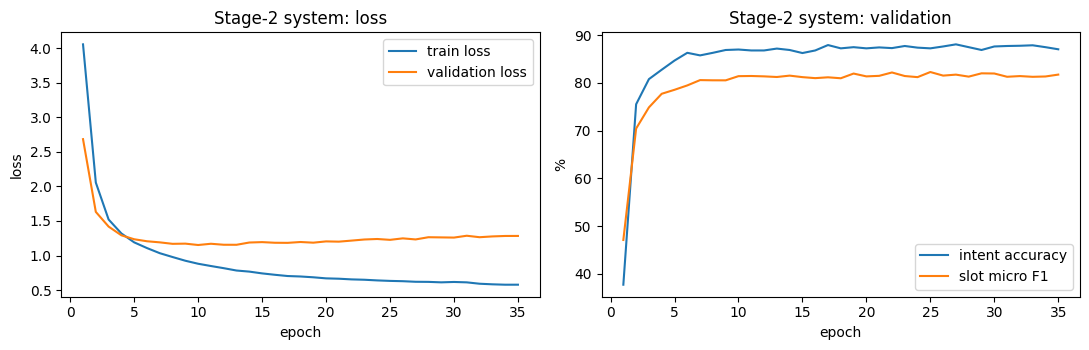

In [20]:
STAGE2_CFG = {**BASELINE_CFG, **ARMS[int(tuning2.mean_combined.idxmax())]}
print('Stage-2 configuration:', STAGE2_CFG)
STAGE2_CKPT = 'stage2_best.pt'
hist2, best_ep2, best_score2 = train(build_model, STAGE2_CFG, STAGE2_CKPT, FINAL_SEED)
print(f'\nBest checkpoint: epoch {best_ep2} | validation combined score {best_score2:.4f} | file {STAGE2_CKPT}')
plot_curves(hist2, 'Stage-2 system')
hist2.to_csv('stage2_history.csv', index=False)

In [21]:
RESULTS['Stage-2 system'], stage2_model = final_eval(build_model, STAGE2_CFG, STAGE2_CKPT, best_score2,
                                                     'Stage-2 system', len(hist2), best_ep2)
error_analysis(stage2_model)

Stage-2 system: total params 6,838,410 | trainable 3,656,010
validation: intent acc 88.05 | slot micro F1 81.71 (matches best epoch 27)
test:       intent acc 85.94 | slot micro F1 79.86
stray I- tags (invalid BIO) in predictions: 0

Predicted-span outcomes: {'exact': 1646, 'missed gold span': 147, 'boundary error': 108, 'spurious': 158, 'type error': 69, 'type + boundary': 36}
recall on gold spans in-vocab: 84.3% of 1787
recall on gold spans oov: 62.2% of 225

Weakest slot types (support >= 20):


,slot,support,precision,recall,f1
12,radio_name,21,50.0,47.6,48.8
14,news_topic,40,61.1,55.0,57.9
8,music_genre,37,72.7,64.9,68.6
6,player_setting,36,70.3,72.2,71.2
4,song_name,23,78.9,65.2,71.4
3,artist_name,45,79.5,68.9,73.8
18,business_type,33,80.0,72.7,76.2
1,food_type,51,73.2,80.4,76.6
22,list_name,37,73.8,83.8,78.5
13,event_name,160,77.6,80.0,78.8



Intent errors: 243, of which 30% stay inside the gold scenario


,gold,predicted,count
0,qa_factoid,general_quirky,7
1,general_quirky,news_query,6
2,calendar_set,calendar_query,6
3,calendar_query,general_quirky,5
4,news_query,qa_factoid,4
5,general_quirky,qa_factoid,4
6,general_quirky,weather_query,4
7,calendar_query,calendar_set,4
8,play_audiobook,play_music,4
9,datetime_convert,datetime_query,3


## 7. Results table (generated from the logged evaluations)

In [22]:
def results_table(results):
    rows = []
    for name, r in results.items():
        for split, key in (('Validation', 'dev'), ('Test', 'test')):
            first = split == 'Validation'
            rows.append({'Model version': name, 'Split': split,
                         'Total # parameters': f"{r['total']:,}" if first else 'Same as above',
                         'Total # trainable parameters': f"{r['trainable']:,}" if first else 'Same as above',
                         'Intent accuracy (%)': f"{r[key]['intent_acc']:.2f}",
                         'Slot micro-F1 (%)': f"{r[key]['slot_f1']:.2f}",
                         'Number of epochs': f"{r['epochs_trained']} (best: {r['best_epoch']})" if first else 'Same as above'})
    return pd.DataFrame(rows)

display(results_table(RESULTS))

,Model version,Split,Total # parameters,Total # trainable parameters,Intent accuracy (%),Slot micro-F1 (%),Number of epochs
0,Stage-1 system,Validation,"6,604,267","3,421,867",87.65,78.83,41 (best: 33)
1,Stage-1 system,Test,Same as above,Same as above,85.94,75.40,Same as above
2,Stage-2 system,Validation,"6,838,410","3,656,010",88.05,81.71,35 (best: 27)
3,Stage-2 system,Test,Same as above,Same as above,85.94,79.86,Same as above
